# 11 — CAP-as-gold evaluation of the frozen codebook (with the v0 benchmark)

**Design rule.** CAP is the gold standard. Per hearing: is our
classification close to the human's, measured as cosine similarity and
rank in the same embedding space? Four tests, five figures — identical
machinery to the archived v0 evaluation, now against the frozen Track-1
codebook (111 topics / 14 themes, sha fd81e781…), with the v0 taxonomy
scored on the same hearings as the benchmark.

1. **Rank-percentile distribution** — the human's subtopic's position in
   our per-hearing ranking of all 213 CAP categories (uniform if random);
2. **Retrieval** — top-k against frequency and random baselines;
3. **Discrete agreement** — NMI at both levels, many-to-one accuracy vs
   design baselines, v1 vs v0 on the common set;
4. **Close-or-far distribution** and the farthest-hearing export.

**Contamination status.** v1 labels frozen before this evaluation; matched
pairs from notebook 07 (titles/dates/committees only).

**Outputs.** printed evaluation; five figures in `paper/figures/`
(replacing the v0 versions); `taxonomy/cap_eval.csv`.

## Setup — matched pairs, CAP texts, both taxonomies' labels

In [1]:
import os
import re
import sys

sys.path.insert(0, "../lib")

import numpy as np
import pandas as pd

from paths import HF_CACHE, ROOT, topics_run_dir

os.environ["HF_HOME"] = str(HF_CACHE)
SEED = 1089
rng = np.random.default_rng(SEED)
TAX = topics_run_dir("taxonomy")
V0 = topics_run_dir("taxonomy_v0")
CAP_DIR = ROOT / "data" / "raw" / "04_comparative_agenda_project"

majors, subs, cur = {}, {}, None
lines = (CAP_DIR / "master_codebook.md").read_text(encoding="latin-1").splitlines()
i = 0
while i < len(lines):
    mM = re.match(r"^(\d+)\.\s+(.+?)\s*$", lines[i])
    mS = re.match(r"^(\d+):\s+(.+?)\s*$", lines[i])
    if mM and int(mM.group(1)) <= 30:
        cur = int(mM.group(1)); majors[cur] = mM.group(2)
    elif mS and cur is not None:
        c, name = int(mS.group(1)), mS.group(2); desc = []
        while i + 1 < len(lines) and re.match(r"^\s+\S", lines[i + 1]):
            nxt = lines[i + 1].strip()
            if nxt.startswith("Description:"):
                desc.append(nxt.split("Description:", 1)[1].strip())
            i += 1
        subs[c] = {"major": cur, "name": name,
                   "text": f"{majors[cur]} — {name}. {' '.join(desc)}"}
    i += 1

match = pd.read_parquet(V0 / "cap_match.parquet")
cap = pd.read_csv(CAP_DIR / "US-Legislative_congressional_hearings-21.7.csv",
                  encoding="latin-1", low_memory=False,
                  usecols=["id", "majortopic", "subtopic"])
v1 = pd.read_parquet(TAX / "hearing_topics_v1.parquet")
v0h = pd.read_parquet(V0 / "track1_hearing_labels_v0.parquet")
t1a = pd.read_parquet(TAX / "track1_assigned.parquet")
r1 = (t1a[t1a["rank"] == 1][["packageId", "phrase"]]
      .drop_duplicates("packageId"))

d = (match[match["tier"] <= 2]
     .merge(v1[["packageId", "primary_label", "primary_theme"]],
            on="packageId")
     .merge(v0h[["packageId", "primary_major", "primary_sub"]],
            on="packageId")
     .merge(r1, on="packageId")
     .merge(cap, left_on="cap_id", right_on="id"))
d["majortopic"] = d["majortopic"].astype(int)
d["subtopic"] = d["subtopic"].astype(int)
d = d[d["subtopic"].isin(subs) & (d["primary_major"] != "OTHER")]
n = len(d)
print(f"evaluation set: {n:,} matched hearings with v1 and v0 labels")

evaluation set: 1,697 matched hearings with v1 and v0 labels


## Embeddings and Test 1–2 — ranks, v1 vs v0 vs raw phrase

In [2]:
import torch
from transformers import AutoModel, AutoTokenizer

import relevance as R

dev = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained(R.ENCODER)
enc = AutoModel.from_pretrained(R.ENCODER, dtype="auto",
                                device_map=dev).eval()

def embed(ts):
    with torch.no_grad():
        return R.encode(list(ts), enc, tok, R.ENCODER).astype(np.float32)

sub_codes = sorted(subs)
E_sub = embed([subs[c]["text"] for c in sub_codes])
pos = {c: k for k, c in enumerate(sub_codes)}
true_col = d["subtopic"].map(pos).to_numpy()

def label_matrix(texts):
    uniq = sorted(set(texts)); E = embed(uniq)
    ix = {t: k for k, t in enumerate(uniq)}
    return E[[ix[t] for t in texts]]

P = label_matrix(d["phrase"])
L1 = label_matrix([f"{t}: {l}" for t, l in
                   zip(d["primary_theme"], d["primary_label"])])
L0 = label_matrix([f"{m.split(' ', 1)[1]}: {s}" for m, s in
                   zip(d["primary_major"], d["primary_sub"])])

def ranks_of(M):
    A = M @ E_sub.T
    return (A > A[np.arange(n), true_col][:, None]).sum(1) + 1, A

ranks_P, A_P = ranks_of(P)
ranks_1, A_1 = ranks_of(L1)
ranks_0, A_0 = ranks_of(L0)
freq = d["subtopic"].value_counts().index.map(pos).to_numpy()

def row(rk):
    return {"top1": (rk <= 1).mean(), "top3": (rk <= 3).mean(),
            "top5": (rk <= 5).mean(), "top5pct": (rk <= 11).mean(),
            "median": float(np.median(rk))}

comp = pd.DataFrame({"raw rank-1 phrase": row(ranks_P),
                     "v1 label (111 topics)": row(ranks_1),
                     "v0 label (79 subs)": row(ranks_0),
                     "frequency baseline": {
                         "top1": np.isin(true_col, freq[:1]).mean(),
                         "top3": np.isin(true_col, freq[:3]).mean(),
                         "top5": np.isin(true_col, freq[:5]).mean(),
                         "top5pct": np.isin(true_col, freq[:11]).mean(),
                         "median": np.nan}}).T
print(comp.round(3).to_string())

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

                        top1   top3   top5  top5pct  median
raw rank-1 phrase      0.270  0.431  0.501    0.631     5.0
v1 label (111 topics)  0.258  0.345  0.391    0.549     9.0
v0 label (79 subs)     0.313  0.412  0.483    0.593     7.0
frequency baseline     0.094  0.230  0.338    0.529     NaN


## Test 3 — discrete agreement, v1 vs v0 on the same hearings

In [3]:
from sklearn.metrics import normalized_mutual_info_score as nmi

def discrete(major_col, sub_col):
    m2o_s = (d.groupby(sub_col)["subtopic"]
             .agg(lambda s: s.value_counts().index[0]))
    m2o_m = (d.groupby(major_col)["majortopic"]
             .agg(lambda s: s.value_counts().index[0]))
    return {
        "nmi_major": nmi(d["majortopic"], d[major_col]),
        "nmi_sub": nmi(d["subtopic"], d[sub_col]),
        "m2o_major": (d[major_col].map(m2o_m).astype(int).to_numpy()
                      == d["majortopic"].to_numpy()).mean(),
        "m2o_sub": (d[sub_col].map(m2o_s).astype(int).to_numpy()
                    == d["subtopic"].to_numpy()).mean(),
        "n_cats": d[sub_col].nunique(),
    }

disc = pd.DataFrame({
    "v1 (14 themes / 111 topics)": discrete("primary_theme",
                                            "primary_label"),
    "v0 (20 majors / 79 subs)": discrete("primary_major", "primary_sub"),
}).T
disc.to_csv(TAX / "cap_eval.csv")
print(disc.round(3).to_string())
print(f"baselines: always-modal major "
      f"{d['majortopic'].value_counts(normalize=True).iloc[0]:.1%}, "
      f"subtopic {d['subtopic'].value_counts(normalize=True).iloc[0]:.1%}")

                             nmi_major  nmi_sub  m2o_major  m2o_sub  n_cats
v1 (14 themes / 111 topics)      0.308    0.557      0.528    0.479   108.0
v0 (20 majors / 79 subs)         0.333    0.546      0.576    0.457    79.0
baselines: always-modal major 33.2%, subtopic 9.4%


## Figure style (house rules, measured layout)

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

from paths import FIGURES

NAVY, RED, GREEN = "#003049", "#A30006", "#7C9885"
CHARCOAL, GRID = "#36454F", "#D0D0D0"
sns.set_theme(style="white", font="serif",
              rc={"font.serif": ["DejaVu Serif", "Times New Roman",
                                 "serif"], "font.size": 10,
                  "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                  "ytick.labelsize": 9.5})
NOTE = (f"Note: {n:,} matched hearings, House Science and Senate Commerce "
        "committees, 1996–2021. Similarity is cosine similarity in the "
        "BAAI/bge-large-en-v1.5 embedding space between the hearing's "
        "extracted topic and each CAP category description; the taxonomy "
        "is the frozen Track-1 codebook v1.0 (111 topics, 14 themes).")
CM_IN = 1 / 2.54

def wrap_to_px(fig, ren, text, width_px, fontsize=8):
    probe = fig.text(0, 0, "", fontsize=fontsize)
    out, curline = [], ""
    for word in text.split():
        trial = f"{curline} {word}".strip()
        probe.set_text(trial)
        if probe.get_window_extent(ren).width <= width_px or not curline:
            curline = trial
        else:
            out.append(curline); curline = word
    out.append(curline); probe.remove()
    return "\n".join(out)

def finish(fig, ax, stem, note, ncol=0, right_x1px=None):
    fig.canvas.draw()
    ren = fig.canvas.get_renderer()
    dpi, W, H = fig.dpi, fig.bbox.width, fig.bbox.height
    gap = 0.3 * CM_IN * dpi
    x0px = ax.yaxis.label.get_window_extent(ren).x0
    x1px = right_x1px if right_x1px is not None else \
        ax.get_window_extent(ren).x1
    xlab_bot = ax.xaxis.label.get_window_extent(ren).y0
    if ncol:
        handles, labels = ax.get_legend_handles_labels()
        leg = fig.legend(handles, labels, frameon=False, loc="upper left",
                         bbox_to_anchor=(x0px / W, (xlab_bot - gap) / H),
                         bbox_transform=fig.transFigure, ncol=ncol,
                         fontsize=9, handlelength=1.8, columnspacing=1.4)
        fig.canvas.draw()
        note_top = leg.get_window_extent(ren).y0 - gap
    else:
        note_top = xlab_bot - gap
    fig.text(x0px / W, note_top / H,
             wrap_to_px(fig, ren, note, x1px - x0px), ha="left", va="top",
             fontsize=8, color="0.35", linespacing=1.4)
    for ext in ("pdf", "svg"):
        fig.savefig(FIGURES / f"{stem}.{ext}", bbox_inches="tight")
    print(f"saved {stem}.pdf/.svg")

def style(ax):
    ax.yaxis.grid(True, color=GRID, linewidth=0.6)
    ax.xaxis.grid(False)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

## Figures 1–2 — rank percentile and retrieval

saved fig_cap_rank_percentile.pdf/.svg


saved fig_cap_retrieval.pdf/.svg


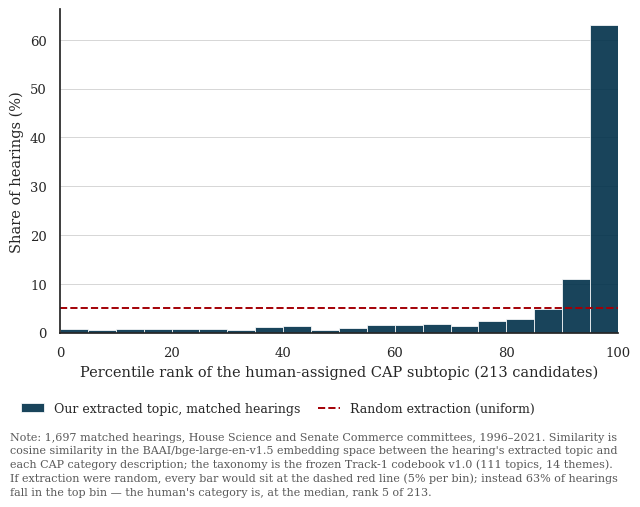

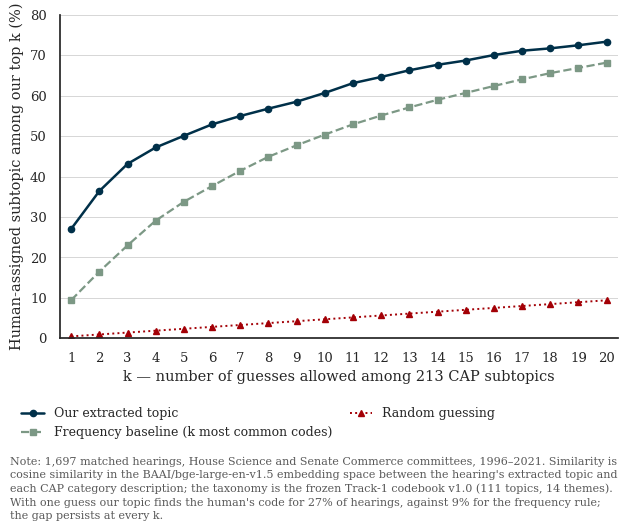

In [5]:
pctile = (len(sub_codes) - ranks_P) / (len(sub_codes) - 1) * 100

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.hist(pctile, bins=np.arange(0, 105, 5), weights=np.full(n, 100 / n),
        color=NAVY, alpha=0.9, edgecolor="white", linewidth=0.6,
        label="Our extracted topic, matched hearings")
ax.axhline(5.0, color=RED, ls="--", lw=1.4,
           label="Random extraction (uniform)")
ax.set_xlabel("Percentile rank of the human-assigned CAP subtopic "
              "(213 candidates)")
ax.set_ylabel("Share of hearings (%)")
ax.set_xlim(0, 100)
ax.margins(x=0)
style(ax)
top_share = (ranks_P <= 11).mean()
finish(fig, ax, "fig_cap_rank_percentile",
       NOTE + f" If extraction were random, every bar would sit at the "
       f"dashed red line (5% per bin); instead {top_share:.0%} of hearings "
       f"fall in the top bin — the human's category is, at the median, "
       f"rank {int(np.median(ranks_P))} of 213.", ncol=2)

ks = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(ks, [(ranks_P <= k).mean() * 100 for k in ks], "-o", color=NAVY,
        ms=4.5, lw=1.8, label="Our extracted topic")
ax.plot(ks, [np.isin(true_col, freq[:k]).mean() * 100 for k in ks], "--s",
        color=GREEN, ms=4, lw=1.6,
        label="Frequency baseline (k most common codes)")
ax.plot(ks, [k / len(sub_codes) * 100 for k in ks], ":^", color=RED,
        ms=4, lw=1.4, label="Random guessing")
ax.set_xticks(ks)
ax.set_xlabel("k — number of guesses allowed among 213 CAP subtopics")
ax.set_ylabel("Human-assigned subtopic among our top k (%)")
ax.set_xlim(0.6, 20.4)
ax.set_ylim(0, 80)
style(ax)
finish(fig, ax, "fig_cap_retrieval",
       NOTE + f" With one guess our topic finds the human's code for "
       f"{(ranks_P <= 1).mean():.0%} of hearings, against "
       f"{np.isin(true_col, freq[:1]).mean():.0%} for the frequency rule; "
       f"the gap persists at every k.", ncol=2)

## Figure 3 — theme × CAP-major crosswalk

saved fig_cap_crosswalk.pdf/.svg


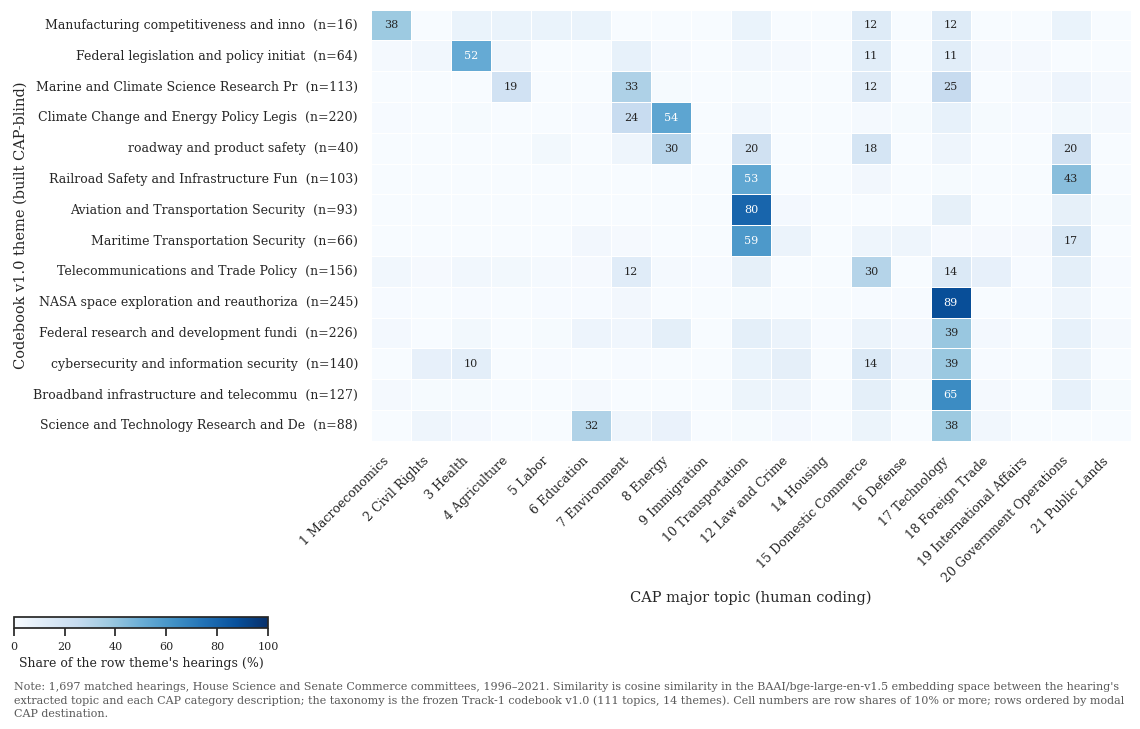

In [6]:
obs = sorted(d["majortopic"].unique())
ct = pd.crosstab(d["primary_theme"], d["majortopic"], normalize="index")
row_modal = d.groupby("primary_theme")["majortopic"].agg(
    lambda s: s.mode()[0])
row_n = d["primary_theme"].value_counts()
order = sorted(ct.index, key=lambda r: (row_modal[r], -row_n[r]))
ct = ct.loc[order, obs] * 100
annot = ct.map(lambda v: f"{v:.0f}" if v >= 10 else "")

fig, ax = plt.subplots(figsize=(9.8, 5.6))
sns.heatmap(ct, cmap="Blues", vmax=100, annot=annot, fmt="",
            annot_kws={"fontsize": 8}, cbar=False,
            linewidths=0.4, linecolor="white", ax=ax)
ax.set_xticks(np.arange(len(obs)) + 0.5)
ax.set_xticklabels([f"{c} {majors[c]}" for c in obs], rotation=45,
                   ha="right", fontsize=9)
ax.set_yticks(np.arange(len(order)) + 0.5)
ax.set_yticklabels([f"{r[:38]}  (n={row_n[r]})" for r in order],
                   rotation=0, fontsize=9)
ax.set_xlabel("CAP major topic (human coding)")
ax.set_ylabel("Codebook v1.0 theme (built CAP-blind)")
fig.canvas.draw()
ren = fig.canvas.get_renderer()
dpi, W, H = fig.dpi, fig.bbox.width, fig.bbox.height
gap = 0.3 * CM_IN * dpi
x0px = ax.yaxis.label.get_window_extent(ren).x0
x1px = ax.get_window_extent(ren).x1
xlab_bot = ax.xaxis.label.get_window_extent(ren).y0
cb_h = 0.02 * H
cbar_ax = fig.add_axes([x0px / W, (xlab_bot - gap - cb_h) / H, 0.26,
                        cb_h / H])
fig.colorbar(ax.collections[0], cax=cbar_ax, orientation="horizontal",
             label="Share of the row theme's hearings (%)")
cbar_ax.tick_params(labelsize=8)
cbar_ax.xaxis.label.set_size(9)
fig.canvas.draw()
cb_bot = min(cbar_ax.get_window_extent(ren).y0,
             cbar_ax.xaxis.label.get_window_extent(ren).y0)
fig.text(x0px / W, (cb_bot - gap) / H,
         wrap_to_px(fig, ren, NOTE + " Cell numbers are row shares of 10% "
                    "or more; rows ordered by modal CAP destination.",
                    x1px - x0px), ha="left", va="top", fontsize=8,
         color="0.35", linespacing=1.4)
for ext in ("pdf", "svg"):
    fig.savefig(FIGURES / f"fig_cap_crosswalk.{ext}", bbox_inches="tight")
print("saved fig_cap_crosswalk.pdf/.svg")

## Figures 4–5 — by-theme boxes and topic↔CAP pairs

saved fig_cap_subtopic_boxes.pdf/.svg


saved fig_cap_subtopic_pairs.pdf/.svg


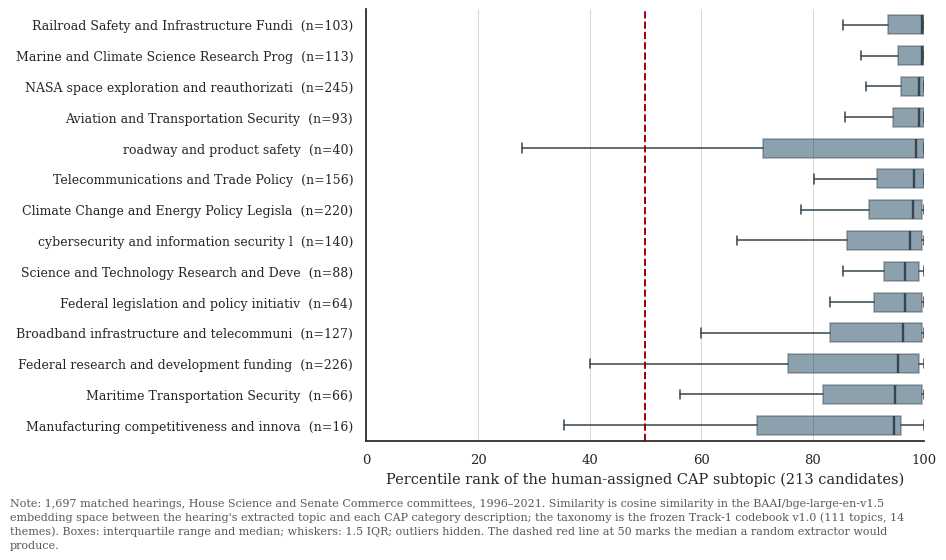

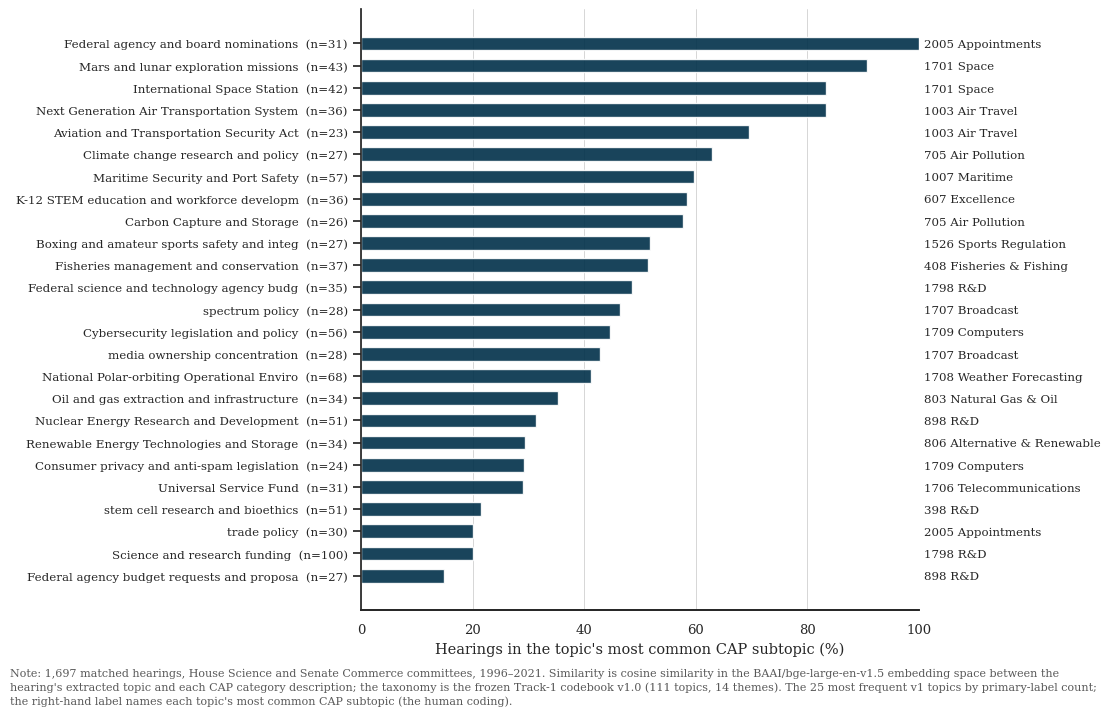

In [7]:
grp = pd.DataFrame({"theme": d["primary_theme"].to_numpy(),
                    "pct": pctile})
order = grp.groupby("theme")["pct"].median().sort_values().index.tolist()
data = [grp.loc[grp["theme"] == m, "pct"].to_numpy() for m in order]

fig, ax = plt.subplots(figsize=(7.2, 5.6))
box = ax.boxplot(data, vert=False, widths=0.62, patch_artist=True,
                 showfliers=False,
                 boxprops={"alpha": 0.45, "edgecolor": CHARCOAL,
                           "linewidth": 1.1},
                 medianprops={"color": CHARCOAL, "linewidth": 1.7},
                 whiskerprops={"color": CHARCOAL, "linewidth": 1.1},
                 capprops={"color": CHARCOAL, "linewidth": 1.1})
for patch in box["boxes"]:
    patch.set_facecolor(NAVY)
ax.axvline(50, color=RED, ls="--", lw=1.4)
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels([f"{m[:40]}  (n={len(v)})"
                    for m, v in zip(order, data)], fontsize=9)
ax.set_xlabel("Percentile rank of the human-assigned CAP subtopic "
              "(213 candidates)")
ax.set_xlim(0, 100)
ax.xaxis.grid(True, color=GRID, linewidth=0.6)
ax.yaxis.grid(False)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
finish(fig, ax, "fig_cap_subtopic_boxes",
       NOTE + " Boxes: interquartile range and median; whiskers: 1.5 IQR; "
       "outliers hidden. The dashed red line at 50 marks the median a "
       "random extractor would produce.")

top_topics = d["primary_label"].value_counts().head(25)
rows = []
for s in top_topics.index:
    g = d.loc[d["primary_label"] == s, "subtopic"]
    modal = g.mode()[0]
    rows.append({"sub": s, "n": len(g),
                 "share": (g == modal).mean() * 100,
                 "cap": f"{modal} {subs[modal]['name']}"})
pairs = pd.DataFrame(rows).sort_values("share")
fig, ax = plt.subplots(figsize=(7.2, 7.8))
y = np.arange(len(pairs))
ax.barh(y, pairs["share"], height=0.62, color=NAVY, alpha=0.9)
ax.set_yticks(y)
ax.set_yticklabels([f"{s[:42]}  (n={k})" for s, k in
                    zip(pairs["sub"], pairs["n"])], fontsize=8.5)
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim())
ax2.set_yticks(y)
ax2.set_yticklabels(pairs["cap"], fontsize=8.5)
ax2.tick_params(axis="y", length=0)
for side in ("top", "right", "left"):
    ax2.spines[side].set_visible(False)
ax.set_xlabel("Hearings in the topic's most common CAP subtopic (%)")
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20))
ax.xaxis.grid(True, color=GRID, linewidth=0.6)
ax.yaxis.grid(False)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.canvas.draw()
_ren = fig.canvas.get_renderer()
right_edge = max(t.get_window_extent(_ren).x1
                 for t in ax2.get_yticklabels())
finish(fig, ax, "fig_cap_subtopic_pairs",
       NOTE + " The 25 most frequent v1 topics by primary-label count; "
       "the right-hand label names each topic's most common CAP subtopic "
       "(the human coding).", right_x1px=right_edge)

## Verification

In [8]:
null_s = A_P[np.arange(n), rng.permutation(true_col)]
s_match = A_P[np.arange(n), true_col]
assert s_match.mean() > null_s.mean() + 6 * null_s.std() / np.sqrt(n)
assert (ranks_1 <= 5).mean() > np.isin(true_col, freq[:5]).mean()

print(f"1) evaluation set : {n:,} matched hearings")
print(f"2) v1 vs v0 (same hearings): "
      f"top1 {(ranks_1 <= 1).mean():.1%} vs {(ranks_0 <= 1).mean():.1%}, "
      f"median rank {int(np.median(ranks_1))} vs "
      f"{int(np.median(ranks_0))}")
print(f"3) raw phrase     : top1 {(ranks_P <= 1).mean():.1%}, median "
      f"{int(np.median(ranks_P))}")
print(f"4) figures        : 5 regenerated against codebook v1.0")

1) evaluation set : 1,697 matched hearings
2) v1 vs v0 (same hearings): top1 25.8% vs 31.3%, median rank 9 vs 7
3) raw phrase     : top1 27.0%, median 5
4) figures        : 5 regenerated against codebook v1.0
